<a href="https://colab.research.google.com/github/smir-nat/Mat-model/blob/main/lab_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Завдання 1

In [2]:
import scipy.signal as signal
import numpy as np

num = [2, -5, 2]
den = [2, 1, 12, 1]

# Знаходження нулів, полюсів та коефіцієнта підсилення (zpk-форма)
zeros, poles, gain = signal.tf2zpk(num, den)

print("Нулі системи (Zeros):", np.round(zeros, 4))
print("Полюси системи (Poles):", np.round(poles, 4))
print("Коефіцієнт підсилення (Gain):", gain)
is_stable = all(np.real(p) < 0 for p in poles)

if is_stable:
    print("\nВисновок: Система СТІЙКА.")
else:
    print("\nВисновок: Система НЕСТІЙКА.")

Нулі системи (Zeros): [2.  0.5]
Полюси системи (Poles): [-0.2081+2.4335j -0.2081-2.4335j -0.0838+0.j    ]
Коефіцієнт підсилення (Gain): 1.0

Висновок: Система СТІЙКА.


<>:49: SyntaxWarning: invalid escape sequence '\o'
<>:49: SyntaxWarning: invalid escape sequence '\o'
/tmp/ipykernel_849/3362162513.py:49: SyntaxWarning: invalid escape sequence '\o'
  axs[2].set_title(f'Відгук на гармонічний сигнал ($\omega={omega}$ рад/с)')


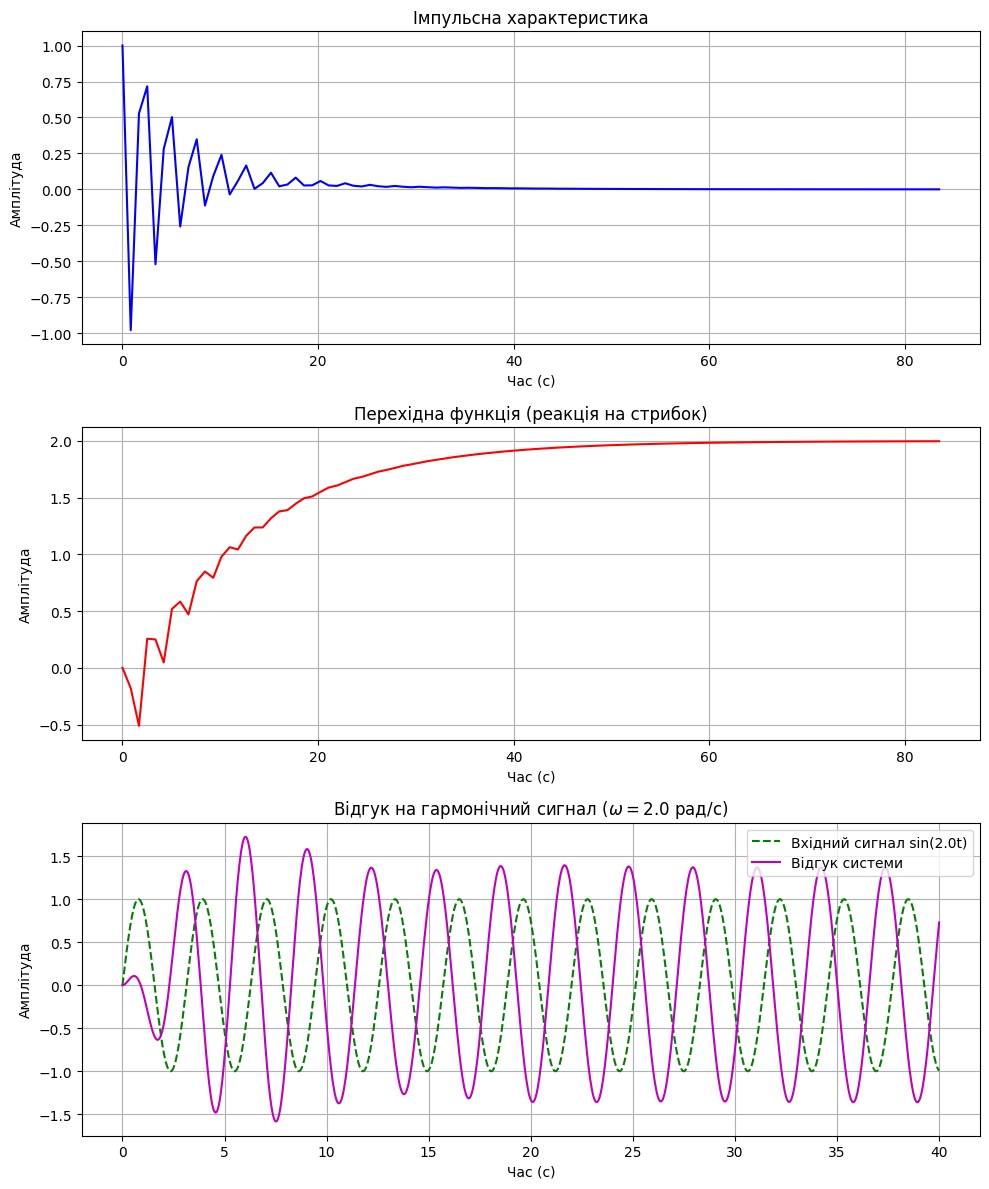

Аналіз для гармонічного сигналу з частотою ω = 2.0 рад/с:
Коефіцієнт посилення (зміна амплітуди): 1.3649
Зсув фази: 2.2424 рад (128.48°)


In [3]:
import scipy.signal as signal
import numpy as np
import matplotlib.pyplot as plt

# Задання системи
num = [2, -5, 2]
den = [2, 1, 12, 1]
sys = signal.TransferFunction(num, den)

# 1. Імпульсна характеристика
t_imp, y_imp = signal.impulse(sys)

# 2. Перехідна функція (реакція на одиничний стрибок)
t_step, y_step = signal.step(sys)

# 3. Відгук на гармонічний сигнал
# Оберемо тестову частоту omega = 2.0 рад/с
omega = 2.0
t_harm = np.linspace(0, 40, 1000)
u_harm = np.sin(omega * t_harm)
t_out, y_harm, _ = signal.lsim(sys, U=u_harm, T=t_harm)

# Обчислення коефіцієнта посилення та зсуву фази для заданої частоти
w, H = signal.freqresp(sys, w=[omega])
magnitude_gain = np.abs(H[0])
phase_shift_rad = np.angle(H[0])
phase_shift_deg = np.degrees(phase_shift_rad)

# Побудова графіків
fig, axs = plt.subplots(3, 1, figsize=(10, 12))

# Графік 1: Імпульсна характеристика
axs[0].plot(t_imp, y_imp, 'b')
axs[0].set_title('Імпульсна характеристика')
axs[0].set_xlabel('Час (с)')
axs[0].set_ylabel('Амплітуда')
axs[0].grid(True)

# Графік 2: Перехідна функція
axs[1].plot(t_step, y_step, 'r')
axs[1].set_title('Перехідна функція (реакція на стрибок)')
axs[1].set_xlabel('Час (с)')
axs[1].set_ylabel('Амплітуда')
axs[1].grid(True)

# Графік 3: Гармонічний відгук
axs[2].plot(t_harm, u_harm, 'g--', label=f'Вхідний сигнал sin({omega}t)')
axs[2].plot(t_out, y_harm, 'm', label='Відгук системи')
axs[2].set_title(f'Відгук на гармонічний сигнал ($\omega={omega}$ рад/с)')
axs[2].set_xlabel('Час (с)')
axs[2].set_ylabel('Амплітуда')
axs[2].legend()
axs[2].grid(True)

plt.tight_layout()
plt.show()

# Вивід результатів аналізу гармонічного сигналу
print(f"Аналіз для гармонічного сигналу з частотою ω = {omega} рад/с:")
print(f"Коефіцієнт посилення (зміна амплітуди): {magnitude_gain:.4f}")
print(f"Зсув фази: {phase_shift_rad:.4f} рад ({phase_shift_deg:.2f}°)")